# Verification: SH finite-difference solver for Love-wave site characterisation

Every test imports the same `love_waves.py` used by the experiments notebook and the app. The PDE is

$$\rho(z)\,u_{tt} = \partial_x(\mu\,\partial_x u) + \partial_z(\mu\,\partial_z u) + f, \qquad \mu = \rho\beta^2,\qquad \mu\,\partial_z u = 0 \text{ at } z = 0,$$

solved by leapfrog with a conservative 2nd-order operator (harmonic averaging of $\mu$ at half-points), an even-mirror free surface and damping sponges. Tests:

1. Homogeneous whole space vs the analytic 2D Green's function: convergence in $\Delta x$ and $\Delta t$.
2. Free surface: half-space response = direct wave + image source.
3. Interface: plane-wave reflection coefficient $R = (Z_1 - Z_2)/(Z_1 + Z_2)$, and why the naive $\beta^2\nabla^2 u$ operator gets it wrong.
4. Love-wave dispersion root finder: limits, cutoffs, residual.
5. Full chain: dispersion picks from an FD shot gather vs the exact roots, and their convergence with grid spacing.
6. Absorbing sponge: reflections from the side boundaries.

In [1]:
import time, numpy as np, matplotlib.pyplot as plt
import love_waves as L
from simulation import analytic_trace          # 2D Green's function (Hankel), shared with the DAS project
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
f0 = 10.0                                       # Ricker peak frequency for tests 1-3 [Hz]
def rel(a, b): return np.linalg.norm(a - b) / np.linalg.norm(b)

## 1. Homogeneous whole space
$\beta = 500$ m/s, no free surface (sponge on all sides), point source in the middle, receivers 20, 40 and 60 m away. In a homogeneous medium the scheme solves $u_{tt} = \beta^2\nabla^2 u + w(t)\delta$, whose solution is the Ricker-convolved 2D Green's function `analytic_trace`. Expected order: 2 in both $\Delta x$ and $\Delta t$.

dx = 2.00 m (  10 pts/wavelength at 25 Hz):  relative L2 error = 1.40e-02


dx = 1.00 m (  20 pts/wavelength at 25 Hz):  relative L2 error = 3.44e-03


dx = 0.50 m (  40 pts/wavelength at 25 Hz):  relative L2 error = 8.56e-04
observed order in dx: 2.02


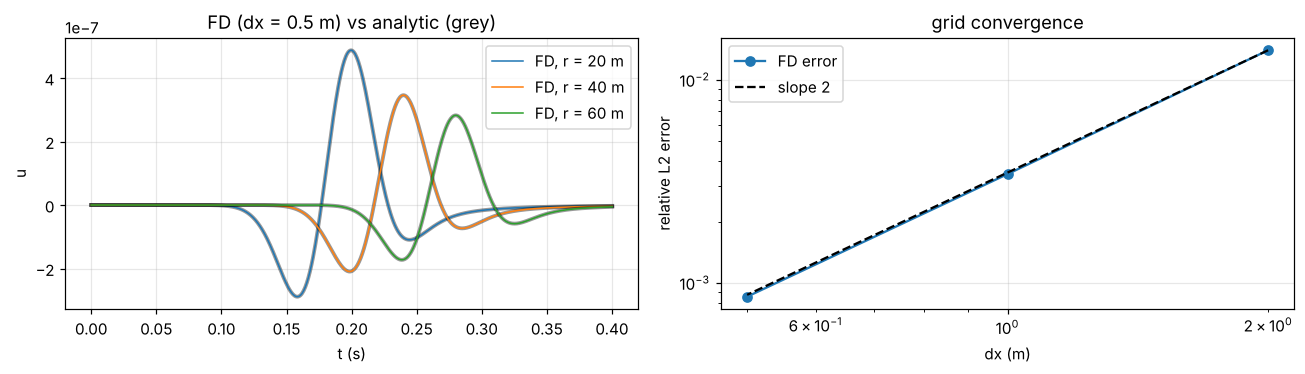

In [2]:
def whole_space(dx, cfl=0.6):
    g = L.Grid(dx=dx, half_width=150, depth=300, side=60, bottom=60, cfl=cfl, free_surface=False)
    beta, rho = np.full((g.nz, g.nx), 500.0), np.full((g.nz, g.nx), 2000.0)
    rec = np.array([[20, 150], [40, 150], [60, 150]], float)       # (x, z); source at (0, 150)
    out = L.simulate_sh(g, beta, rho, (0, 150), f0, 0.4, points=rec)
    ana = np.column_stack([analytic_trace(r, out["t"], f0, 500.0) for r in (20, 40, 60)])
    return out, ana

dxs, err = [2.0, 1.0, 0.5], []
for dx in dxs:
    out, ana = whole_space(dx)
    err.append(rel(out["points"], ana))
    print(f"dx = {dx:4.2f} m ({500 / 25 / dx:4.0f} pts/wavelength at 25 Hz):  relative L2 error = {err[-1]:.2e}")
print(f"observed order in dx: {np.polyfit(np.log(dxs), np.log(err), 1)[0]:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for k, r in enumerate((20, 40, 60)):
    ax[0].plot(out["t"], ana[:, k], "k", lw=2.5, alpha=0.4)
    ax[0].plot(out["t"], out["points"][:, k], lw=1, label=f"FD, r = {r} m")
ax[0].set(xlabel="t (s)", ylabel="u", title="FD (dx = 0.5 m) vs analytic (grey)"); ax[0].legend()
ax[1].loglog(dxs, err, "o-", label="FD error"); ax[1].loglog(dxs, err[0] * (np.array(dxs) / dxs[0])**2, "k--", label="slope 2")
ax[1].set(xlabel="dx (m)", ylabel="relative L2 error", title="grid convergence"); ax[1].legend(); plt.tight_layout()

For $\Delta t$ the spatial error dominates (and partly cancels the temporal error, a known property of leapfrog), so we test **self-convergence** at fixed $\Delta x$: the difference from a run with a much smaller time step should fall as $\Delta t^2$.

In [3]:
ref, _ = whole_space(1.0, cfl=0.05)
cfls, derr = [0.6, 0.3, 0.15], []
for cfl in cfls:
    out, _ = whole_space(1.0, cfl)
    n = min(len(out["t"]), len(ref["t"]))
    # resample the reference onto this run's time samples
    r = np.column_stack([np.interp(out["t"], ref["t"], ref["points"][:, k]) for k in range(3)])
    derr.append(rel(out["points"], r))
    print(f"CFL = {cfl:4.2f}:  difference from CFL 0.05 run = {derr[-1]:.2e}")
print(f"observed order in dt: {np.polyfit(np.log(cfls), np.log(derr), 1)[0]:.2f}")

CFL = 0.60:  difference from CFL 0.05 run = 1.89e-03


CFL = 0.30:  difference from CFL 0.05 run = 4.62e-04


CFL = 0.15:  difference from CFL 0.05 run = 1.06e-04
observed order in dt: 2.08


## 2. Free surface: image source
In a homogeneous half-space with $\partial_z u = 0$ at $z=0$, the field of a source at depth $z_s$ is the whole-space field plus that of an image source at $-z_s$. This tests the ghost-row boundary, including a receiver *on* the surface where the two contributions are equal.

dx = 2.00 m:  relative L2 error (direct + image) = 1.50e-02


dx = 1.00 m:  relative L2 error (direct + image) = 3.52e-03


dx = 0.50 m:  relative L2 error (direct + image) = 8.77e-04
observed order in dx: 2.05


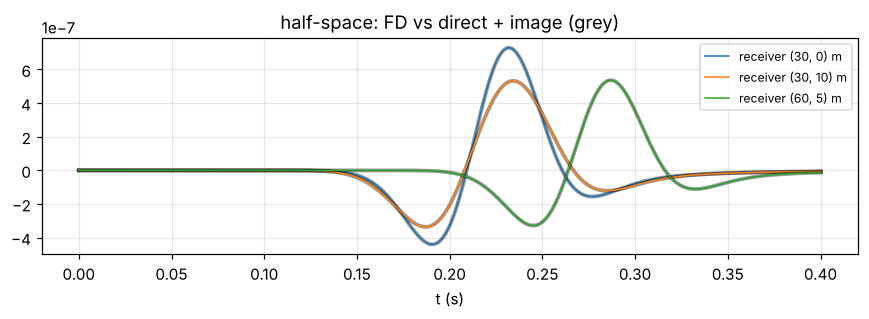

In [4]:
zs, rec = 20.0, np.array([[30, 0], [30, 10], [60, 5]], float)
err = []
for dx in dxs:
    g = L.Grid(dx=dx, half_width=150, depth=150, side=60, bottom=60)
    beta, rho = np.full((g.nz, g.nx), 500.0), np.full((g.nz, g.nx), 2000.0)
    out = L.simulate_sh(g, beta, rho, (0, zs), f0, 0.4, points=rec)
    ana = np.column_stack([analytic_trace(np.hypot(x, z - zs), out["t"], f0, 500.0) +
                           analytic_trace(np.hypot(x, z + zs), out["t"], f0, 500.0) for x, z in rec])
    err.append(rel(out["points"], ana))
    print(f"dx = {dx:4.2f} m:  relative L2 error (direct + image) = {err[-1]:.2e}")
print(f"observed order in dx: {np.polyfit(np.log(dxs), np.log(err), 1)[0]:.2f}")
fig, ax = plt.subplots(figsize=(8, 3))
for k, (x, z) in enumerate(rec):
    ax.plot(out["t"], ana[:, k], "k", lw=2.5, alpha=0.4); ax.plot(out["t"], out["points"][:, k], lw=1, label=f"receiver ({x:.0f}, {z:.0f}) m")
ax.set(xlabel="t (s)", title="half-space: FD vs direct + image (grey)"); ax.legend(fontsize=8); plt.tight_layout()

## 3. Interface: reflection coefficient
A plane SH wave at normal incidence in the soil ($\beta_1 = 250$ m/s, $\rho_1 = 1800$) hits the bedrock ($\beta_2 = 800$ m/s, $\rho_2 = 2100$). Continuity of $u$ and of the traction $\mu\,\partial_z u$ gives the displacement reflection coefficient

$$R = \frac{Z_1 - Z_2}{Z_1 + Z_2}, \qquad Z = \rho\beta \quad\Rightarrow\quad R = -0.577.$$

At $\Delta x = 2$ m the 10 Hz pulse has only 5 points per wavelength in the soil, so the test starts at 1 m. The grid is periodic in $x$ (a 1D problem using the same 2D code), the source is a horizontal line 100 m above the interface, and the top is a sponge so the only reflection is from the interface. The naive operator $\beta^2(u_{xx} + u_{zz})$ instead enforces continuity of $\partial_z u$, which gives $R = (\beta_2 - \beta_1)/(\beta_2 + \beta_1) = +0.524$: the **wrong sign** and the wrong size. This is why the DAS project's constant-coefficient Laplacian cannot be reused here.

exact R = -0.5775     (naive-operator theory: +0.5238)


dx = 1.0 m:  conservative R = -0.5626 (error 1.5e-02)   naive R = +0.5053


dx = 0.5 m:  conservative R = -0.5764 (error 1.1e-03)   naive R = +0.5227


dx = 0.2 m:  conservative R = -0.5768 (error 6.7e-04)   naive R = +0.5243


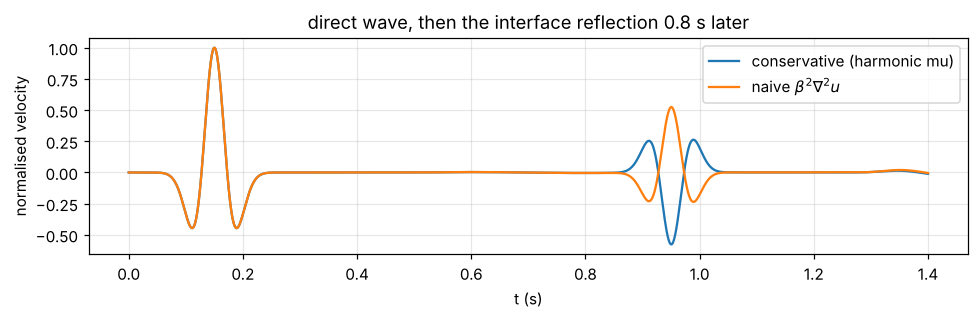

In [5]:
site_R = L.Site(b1=250, b2=800, H=150.0, r1=1800, r2=2100)
Z1, Z2 = 1800 * 250, 2100 * 800
R_exact, R_naive = (Z1 - Z2) / (Z1 + Z2), (800 - 250) / (800 + 250)

def reflection(conservative, dx):
    g = L.Grid(dx=dx, half_width=2 * dx, depth=300, bottom=100, periodic_x=True, free_surface=False)
    beta, rho, muz = L.layered_grid(site_R, g)
    out = L.simulate_sh(g, beta, rho, (0, 50), f0, 1.4, points=[[0, 50]], src_row=True,
                        muz=muz if conservative else None, conservative=conservative)
    t, v = out["t"], np.gradient(out["points"][:, 0], out["t"])   # particle velocity
    t0 = 1.5 / f0
    d, r = t < t0 + 0.4, (t > t0 + 0.5) & (t < t0 + 1.2)          # direct / reflected windows
    peak = lambda m: v[m][np.argmax(np.abs(v[m]))]
    return peak(r) / peak(d), t, v

print(f"exact R = {R_exact:+.4f}     (naive-operator theory: {R_naive:+.4f})")
for dx in [1.0, 0.5, 0.25]:
    Rc, Rn = reflection(True, dx)[0], reflection(False, dx)[0]
    print(f"dx = {dx:3.1f} m:  conservative R = {Rc:+.4f} (error {abs(Rc - R_exact):.1e})   naive R = {Rn:+.4f}")
fig, ax = plt.subplots(figsize=(9, 3))
for cons, lab in [(True, "conservative (harmonic mu)"), (False, r"naive $\beta^2\nabla^2u$")]:
    _, t, v = reflection(cons, 0.25); ax.plot(t, v / np.abs(v).max(), label=lab)
ax.set(xlabel="t (s)", ylabel="normalised velocity", title="direct wave, then the interface reflection 0.8 s later"); ax.legend(); plt.tight_layout()

## 4. Love-wave dispersion relation
For the default site (15 m of 250 m/s soil over 800 m/s bedrock) we check that the root finder returns a true root of $\tan(\omega H\eta_1) = \mu_2\eta_2/(\mu_1\eta_1)$, that the fundamental tends to $\beta_2$ at low frequency and to $\beta_1$ at high frequency, and that mode $n$ starts at $c = \beta_2$ at the cutoff $f_n = n/(2H\sqrt{\beta_1^{-2} - \beta_2^{-2}})$.

max relative residual of the dispersion relation: 2.0e-11
fundamental: c(0.1 Hz) = 800.0 m/s (beta2 = 800),  c(200 Hz) = 250.1 m/s (beta1 = 250)
mode 1: cutoff  8.77 Hz;  c just above = 800.0 m/s (beta2 = 800);  exists just below: False
mode 2: cutoff 17.55 Hz;  c just above = 800.0 m/s (beta2 = 800);  exists just below: False
mode 3: cutoff 26.32 Hz;  c just above = 800.0 m/s (beta2 = 800);  exists just below: False


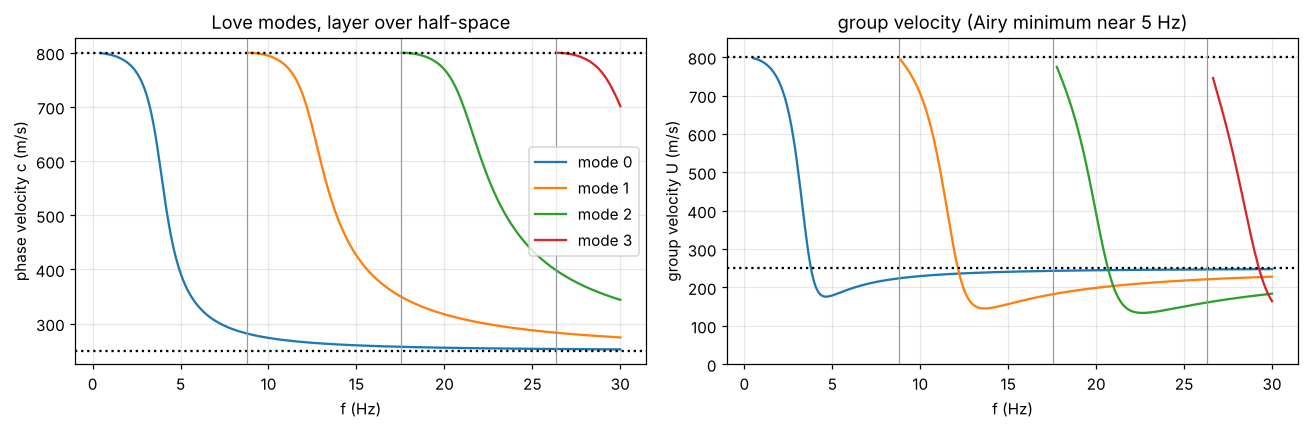

In [6]:
site = L.Site()
f = np.linspace(0.5, 30, 300)
modes = L.love_modes(f, site, 4)
res = []
for n in range(4):
    for fi, c in zip(f, modes[n]):
        if np.isfinite(c):
            e1, e2 = np.sqrt(site.b1**-2 - c**-2), np.sqrt(c**-2 - site.b2**-2)
            lhs = np.tan(2 * np.pi * fi * site.H * e1)
            rhs = site.r2 * site.b2**2 * e2 / (site.r1 * site.b1**2 * e1)
            res.append(abs(lhs - rhs) / (1 + abs(rhs)))
print(f"max relative residual of the dispersion relation: {max(res):.1e}")
print(f"fundamental: c(0.1 Hz) = {L.love_root(0.1, site):.1f} m/s (beta2 = {site.b2:.0f}),  c(200 Hz) = {L.love_root(200, site):.1f} m/s (beta1 = {site.b1:.0f})")
for n in (1, 2, 3):
    fc = site.cutoff(n)
    print(f"mode {n}: cutoff {fc:5.2f} Hz;  c just above = {L.love_root(fc * 1.0001, site, n):.1f} m/s (beta2 = {site.b2:.0f});  exists just below: {np.isfinite(L.love_root(fc * 0.999, site, n))}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n in range(4):
    ax[0].plot(f, modes[n], label=f"mode {n}")
    ax[1].plot(f, [L.group_velocity(fi, site, n) if np.isfinite(L.love_root(fi, site, n)) and fi > site.cutoff(n) * 1.01 else np.nan for fi in f])
for a in ax:
    [a.axhline(b, color="k", ls=":") for b in (site.b1, site.b2)]
    [a.axvline(site.cutoff(n), color="0.6", lw=0.8) for n in (1, 2, 3)]
ax[0].set(xlabel="f (Hz)", ylabel="phase velocity c (m/s)", title="Love modes, layer over half-space"); ax[0].legend()
ax[1].set(xlabel="f (Hz)", ylabel="group velocity U (m/s)", title="group velocity (Airy minimum near 5 Hz)", ylim=(0, 850)); plt.tight_layout()

## 5. Full chain: FD shot gather → phase-shift transform → picks vs exact roots
One FD impulse at the surface of the layered model, recorded at offsets 50–350 m, then the phase-shift dispersion image and its peak. Between 5 and 12 Hz the fundamental dominates and the pick should match `love_root`. The remaining error is the FD numerical dispersion, which makes waves slightly *slow* and should fall as $\Delta x^2$, i.e. as (points per wavelength)$^{-2}$. Below about 4 Hz the 300 m aperture is less than about one wavelength and the pick is no longer meaningful (studied in the experiments notebook). This is the slowest cell (three FD runs, about 5 minutes at $\Delta x = 0.5$ m).

dx = 2.0 m: FD run   7.9 s;  pick error 5-12 Hz: mean -0.69 %,  at 12 Hz -1.36 %


dx = 1.0 m: FD run  33.1 s;  pick error 5-12 Hz: mean -0.25 %,  at 12 Hz -0.37 %


dx = 0.5 m: FD run 325.0 s;  pick error 5-12 Hz: mean -0.08 %,  at 12 Hz -0.11 %
observed order of the 12 Hz error in dx: 1.83


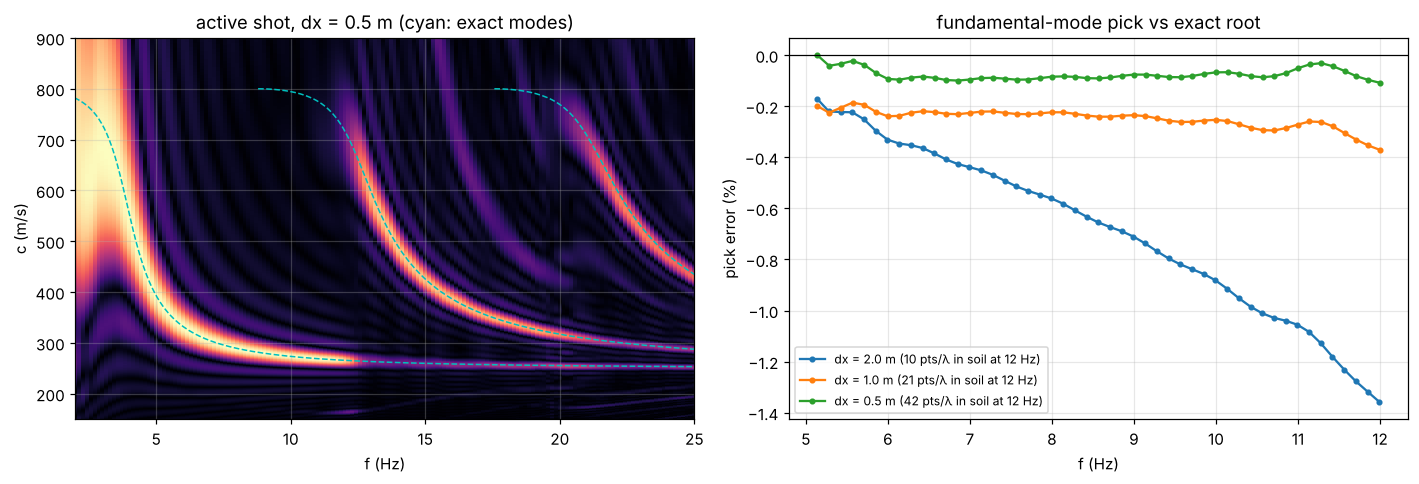

In [7]:
c_trial = np.linspace(150, 900, 751)
off = np.arange(50, 351, 2.0)
chain, lines = {}, {}
for dx in [2.0, 1.0, 0.5]:
    t0 = time.time()
    ll = L.LoveLine(grid=L.Grid(dx=dx))
    img = L.phase_shift(ll.green(off), off, ll.f, c_trial)
    fp, cp = L.pick_ridge(img, c_trial, ll.f, 5, 12)
    chain[dx] = (fp, cp / np.array([L.love_root(x, site) for x in fp]) - 1)
    lines[dx] = ll
    print(f"dx = {dx:3.1f} m: FD run {time.time() - t0:5.1f} s;  pick error 5-12 Hz: "
          f"mean {100 * chain[dx][1].mean():+.2f} %,  at 12 Hz {100 * chain[dx][1][-1]:+.2f} %")
e12 = [abs(chain[dx][1][-1]) for dx in chain]
print(f"observed order of the 12 Hz error in dx: {np.polyfit(np.log(list(chain)), np.log(e12), 1)[0]:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ll = lines[0.5]
img = L.phase_shift(ll.green(off), off, ll.f, c_trial)
ax[0].pcolormesh(ll.f, c_trial, img.T, cmap="magma", shading="auto")
for n in range(3):
    ax[0].plot(f, modes[n], "c--", lw=1)
ax[0].set(xlim=(2, 25), ylim=(150, 900), xlabel="f (Hz)", ylabel="c (m/s)", title="active shot, dx = 0.5 m (cyan: exact modes)")
for dx, (fp, e) in chain.items():
    ax[1].plot(fp, 100 * e, "o-", ms=3, label=f"dx = {dx} m ({site.b1 / 12 / dx:.0f} pts/λ in soil at 12 Hz)")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(xlabel="f (Hz)", ylabel="pick error (%)", title="fundamental-mode pick vs exact root"); ax[1].legend(fontsize=8)
plt.tight_layout()

Above about 12.6 Hz the image peak in the active shot jumps from the fundamental onto mode 1. That is not a numerical error: for this strong-contrast site a surface source puts more energy into mode 1 at those frequencies (the experiments notebook uses this as a failure case).

## 6. Absorbing sponge
Love waves are trapped near the surface and travel sideways, so the side sponges matter most. We compare the surface record at offsets 0–400 m with a run on a much wider grid (900 m half-width, whose side reflections arrive after the record ends).

In [8]:
o = np.arange(0, 401, 10.0)
a = L.LoveLine(grid=L.Grid(dx=2.0))
b = L.LoveLine(grid=L.Grid(dx=2.0, half_width=900, side=300))
_, ua = a.to_time(a.green(o)); _, ub = b.to_time(b.green(o))
print(f"side sponge {a.grid.side:.0f} m: relative difference from the wide-grid run = {rel(ua, ub):.2%}")

side sponge 250 m: relative difference from the wide-grid run = 0.61%


## Summary
| test | result |
|---|---|
| whole space vs analytic 2D Green's function | 2nd order in $\Delta x$; 2nd-order self-convergence in $\Delta t$ |
| free surface vs image source | 2nd order, about 0.1% at 0.5 m |
| interface reflection coefficient | conservative operator converges to $R = -0.577$; naive operator gives $+0.52$ |
| Love dispersion root finder | residual near machine precision, correct limits and cutoffs |
| full chain (FD → phase shift → pick) | fundamental within a fraction of a percent at 5–12 Hz, converging as $\Delta x^2$ |
| side sponge | below 1% reflection |

The experiments use $\Delta x = 1$ m, where the solver error on the fundamental is about −0.2 to −0.4%. Any bias larger than that comes from the noise field, the array or the picking, not from the solver.